In [28]:
from __future__ import annotations
from typing import TypedDict, List, Annotated
import operator

from pydantic import Field, BaseModel
from langgraph.graph import START, END, StateGraph
from langgraph.types import Send

from langchain_groq import ChatGroq
from langchain_google_genai import ChatGoogleGenerativeAI
from langchain_core.messages import SystemMessage, HumanMessage

from langgraph.checkpoint.memory import InMemorySaver
from langgraph.types import interrupt, Command

from dotenv import load_dotenv
load_dotenv()

True

In [29]:
class Task(BaseModel):
    id: int
    title: str
    brief: str = Field(description="What to cover")

In [30]:
class Plan(BaseModel):
    blog_title: str
    tasks: List[Task]

In [31]:
class State(TypedDict):
    topic: str
    plan: Plan
    # reducer: results from workers get concatenated automatically
    sections: Annotated[List[str],operator.add] 
    final: str

    feedback: str
    approved: bool

    final_after_review: str

In [32]:
# llm = ChatGroq(model="openai/gpt-oss-120b")
llm = ChatGoogleGenerativeAI(model="gemini-3.5-flash-lite")

ORCHESTRATOR - MAKES PLAN FOR THE BLOG AND STORES IN PLAN OBJECT

In [33]:
def orchestrator(state: State):
    plan = llm.with_structured_output(Plan).invoke(
        [
            SystemMessage(content=("Create a blog plan with 1-2 sections on the following topic")),
            HumanMessage(content=f"Topic: {state['topic']}")
        ]
    )

    return {"plan":plan}

FANOUT - THE NUMBER OF WORKER DEPENDS ON THE NUMBER OF BLOG SECTION, IT IS DECIDED DYNAMICALLY

- Each worker knows it's task to perform, entire blog topic, entire blog plan; So that it can do it's worker properly

In [34]:
def fanout(state:State):
    return [Send("worker",{"task":task, "topic":state["topic"], "plan":state['plan']})
            for task in state['plan'].tasks]

In [35]:
def worker(payload: dict)-> dict:

    task = payload["task"]
    topic = payload['topic']
    plan = payload["plan"]

    blog_title = plan.blog_title

    section_md = llm.invoke(
        [
            SystemMessage(content="Write one clean Markdown section"),
            HumanMessage(
                content=(
                    f"Blog Title: {blog_title}\n"
                    f"Topic:{topic}\n"
                    f"Section:{task.title}\n"
                    f"Brief:{task.brief}\n"
                )
            )
        ]
    ).content[0]["text"]
    
    return {"sections": [section_md]}
    

REDUCER - STITCHES ALL THE SECTIONS FROM THE WOKER AND CONCATINATE'S IT

In [36]:
from pathlib import Path

def reducer(state: State)->dict:

    title = state['plan'].blog_title
    body = "\n\n".join(state['sections'])

    final_md =f"# {title} \n\n {body}"

    # Save to File
    filename = title.lower().replace(" ","_")+".md"
    output_path = Path(filename)
    output_path.write_text(final_md, encoding="utf-8")

    return {"final":final_md}

In [37]:
def human_review(state: State):
    decision = interrupt({
        "blog": state["final"],
        "question":"Do you want to approve this blog?",
        "options":["approve","revise"],
        "instruction":"Approve the blog, or provide suggestions"
    })

    if decision["approved"]:
        return {"feedback":"" ,"approved":True}

    else:
        return {"feedback":decision["feedback"], "approved":False}

In [38]:
REVISE_BLOG = """
        You are a blog editor.
        Revise the existing blog according to the human's feedback.

        Requirements:
        - Preserve useful existing content.
        - Apply the requested changes.
        - Return the complete revised blog in Markdown.
        - Do not return explanations about the changes.
        """

In [39]:
def revise_blog(state: State):
    blog_to_review = (state.get("final_after_review") or state["final"])
    title = state['plan'].blog_title

    reponse = llm.invoke([
        SystemMessage(content=REVISE_BLOG),
        HumanMessage(content=f"""
        Current Blog:\n {blog_to_review},
        Human feedback:\n {state['feedback']}
        """)
        ]).content

    final_blog_after_review = reponse[0]["text"]

# Save The Final Blog

    filename = title.lower().replace(" ","_")+"AFTER_REVIEW.md"
    output_path = Path(filename)
    output_path.write_text(final_blog_after_review, encoding="utf-8")

    return {"final_after_review":final_blog_after_review, "approved":False, "feedback":""}

In [40]:

def route_after_review(state: State) -> str:
    if state["approved"]:
        return "approved"
    return "revise"


In [41]:
g = StateGraph(State)
g.add_node("orchestrator",orchestrator)
g.add_node("worker",worker)
g.add_node("reducer",reducer)
g.add_node("human_review",human_review)
g.add_node("revise_blog", revise_blog)

checkpointer = InMemorySaver()

In [42]:
g.add_edge(START,"orchestrator")
g.add_conditional_edges("orchestrator", fanout, ["worker"])
g.add_edge("worker","reducer")
g.add_edge("reducer","human_review")

g.add_conditional_edges("human_review",route_after_review,{"approved":END, "revise":"revise_blog"})

g.add_edge("revise_blog","human_review")

app = g.compile(checkpointer=checkpointer)

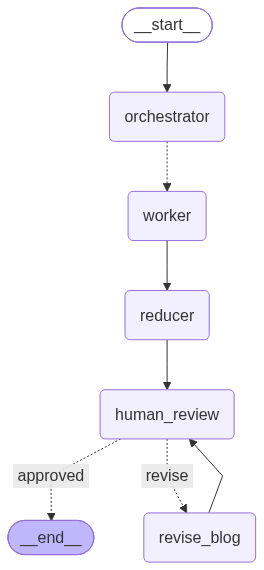

In [43]:
app

In [44]:
config = {"configurable":{"thread_id":"123"}}
out = app.invoke({"topic":"Write A blog on Python"},config=config)

In [46]:
out

{'topic': 'Write A blog on Python',
 'plan': Plan(blog_title="Getting Started with Python: A Beginner's Guide", tasks=[Task(id=1, title='Why Learn Python?', brief='Discuss the versatility, readability, and high demand of Python in the job market, including applications in web development and data science.'), Task(id=2, title='Writing Your First Python Script', brief="Provide a step-by-step guide on setting up Python, writing a simple 'Hello, World!' program, and understanding basic syntax.")]),
 'sections': ["## Why Learn Python?\n\nWhether you are looking to pivot into tech, automate boring daily tasks, or build the next big application, Python is the ultimate language to start your journey. But what makes it so special for beginners and seasoned developers alike? \n\nHere are three key reasons why Python remains the world’s most popular programming language:\n\n*   **Exceptional Readability:** Python was designed with human readability in mind. Its syntax closely resembles plain Engl

In [21]:
out["__interrupt__"][0].value

{'blog': '# Getting Started with Python Programming \n\n ## Introduction to Python\n\nPython has taken the programming world by storm, evolving from a simple scripting language into the undisputed heavyweight champion of software development, data science, and artificial intelligence. But what makes this friendly, snake-named language so universally adored?\n\n### A Brief History of Python\nPython was conceived in the late 1980s by **Guido van Rossum** at Centrum Wiskunde & Informatica (CWI) in the Netherlands as a successor to the ABC programming language. Van Rossum officially released Python in 1991. Interestingly, the language wasn\'t named after the terrifying reptile, but rather after Van Rossum\'s favorite comedy troupe: *Monty Python\'s Flying Circus*. \n\nFrom its inception, Python was designed with a core philosophy emphasizing code readability and simplicity. Its syntax allowed programmers to express concepts in fewer lines of code than would be possible in languages like C+

## RESUME WITHOUT ANY FEEDBACK

In [22]:
result = app.invoke(
    Command(resume={
        "approved": True,
        "feedback": ""
    }),
    config=config
)

Deserializing unregistered type __main__.Plan from checkpoint. This will be blocked in a future version. Set LANGGRAPH_STRICT_MSGPACK=true to block now, or add to allowed_msgpack_modules to allow explicitly: [('__main__', 'Plan')]


In [25]:
result

{'topic': 'Write A blog on Python',
 'plan': Plan(blog_title='Getting Started with Python Programming', tasks=[Task(id=1, title='Introduction to Python', brief='Cover the basics of Python, its history, and why it is one of the most popular programming languages today.'), Task(id=2, title='Setting Up Your First Environment', brief='Guide the reader through installing Python, setting up an IDE like VS Code or PyCharm, and writing a simple Hello World program.')]),
 'sections': ["## Introduction to Python\n\nPython has taken the programming world by storm, evolving from a simple scripting language into the undisputed heavyweight champion of software development, data science, and artificial intelligence. But what makes this friendly, snake-named language so universally adored?\n\n### A Brief History of Python\nPython was conceived in the late 1980s by **Guido van Rossum** at Centrum Wiskunde & Informatica (CWI) in the Netherlands as a successor to the ABC programming language. Van Rossum 

## RESUME WITH GIVING FEEDBACK

In [47]:
result = app.invoke(Command(resume={
    "approved":False,
    "feedback":"Add an example Code in the blog"
}),config=config)

In [48]:
print(result)

{'topic': 'Write A blog on Python', 'plan': Plan(blog_title="Getting Started with Python: A Beginner's Guide", tasks=[Task(id=1, title='Why Learn Python?', brief='Discuss the versatility, readability, and high demand of Python in the job market, including applications in web development and data science.'), Task(id=2, title='Writing Your First Python Script', brief="Provide a step-by-step guide on setting up Python, writing a simple 'Hello, World!' program, and understanding basic syntax.")]), 'sections': ["## Why Learn Python?\n\nWhether you are looking to pivot into tech, automate boring daily tasks, or build the next big application, Python is the ultimate language to start your journey. But what makes it so special for beginners and seasoned developers alike? \n\nHere are three key reasons why Python remains the world’s most popular programming language:\n\n*   **Exceptional Readability:** Python was designed with human readability in mind. Its syntax closely resembles plain Englis

In [27]:
print(result['final'])

# Getting Started with Python Programming 

 ## Introduction to Python

Python has taken the programming world by storm, evolving from a simple scripting language into the undisputed heavyweight champion of software development, data science, and artificial intelligence. But what makes this friendly, snake-named language so universally adored?

### A Brief History of Python
Python was conceived in the late 1980s by **Guido van Rossum** at Centrum Wiskunde & Informatica (CWI) in the Netherlands as a successor to the ABC programming language. Van Rossum officially released Python in 1991. Interestingly, the language wasn't named after the terrifying reptile, but rather after Van Rossum's favorite comedy troupe: *Monty Python's Flying Circus*. 

From its inception, Python was designed with a core philosophy emphasizing code readability and simplicity. Its syntax allowed programmers to express concepts in fewer lines of code than would be possible in languages like C++ or Java.

### Why Is

In [50]:
print(result['final_after_review'])

# Getting Started with Python: A Beginner's Guide 

## Why Learn Python?

Whether you are looking to pivot into tech, automate boring daily tasks, or build the next big application, Python is the ultimate language to start your journey. But what makes it so special for beginners and seasoned developers alike? 

Here are three key reasons why Python remains the world’s most popular programming language:

*   **Exceptional Readability:** Python was designed with human readability in mind. Its syntax closely resembles plain English, which means you spend less time deciphering complex code and more time solving actual problems.
*   **Unmatched Versatility:** Python isn't pigeonholed into one niche. It is the powerhouse behind **web development** (using frameworks like Django and Flask), the undisputed king of **data science and machine learning** (with libraries like Pandas, TensorFlow, and Scikit-Learn), and a go-to tool for automation, cybersecurity, and scripting.
*   **High Market Dema